In [3]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
from dask.diagnostics import ProgressBar
import rasterio.features as features
import glob
from netCDF4 import Dataset
from shapely.geometry import box

## Open data

In [4]:
path_refl_data = '/mnt/data3/nfs4/cci_snow_3/composites/beta/CAC/AVN14/2000/CACin200004*.nc'

In [5]:
path_angle_data = '/mnt/data3/nfs4/cci_snow_3/composites/beta/CAA/AVN14/2000/CAAin200004*.nc'

In [6]:
path_cloud_data = '/mnt/data3/nfs4/cci_snow_3/composites/beta/CMA/AVN14/2000/CMAin200004*.nc'

In [7]:
path_map = '/scratch/mpekkala/Transmissivity_maps/World_Continents/World_Continents.shp'

In [8]:
path_Kemijoki = '/scratch/mpekkala/Transmissivity_maps/Kemijoki_4326/Kemijoki_grid_5000.shp'

In [9]:
path_Kemijoki_MODIS = '/scratch/mpekkala/Transmissivity_maps/MODIS_transmissivity/Baltic_trans2_005deg_2011_2Kemijokigrid_1km.tif'

In [10]:
path_ENVEO_transmissivity = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/20200710_CANOPY_CORRECTION_LAYER_TCD_LCCCI_2000_v01_005deg.tif'

In [11]:
path_ENVEO_nodata = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/DEM_global_SRTMV41_TDMX_llwgs84_avg_005deg_nodata.tif'

In [12]:
path_ENVEO_DEM = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/DEM_lt_1000_lat_pm_15.tif'

In [13]:
path_ENVEO_icemask = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/icemask50.tif'

In [14]:
path_ENVEO_watermask = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/watermask50.tif'

In [15]:
ds_refl = xr.open_mfdataset(path_refl_data)

/tmp/ipykernel_433137/4140158708.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_refl = xr.open_mfdataset(path_refl_data)


In [16]:
ds_angle = xr.open_mfdataset(path_angle_data)

/tmp/ipykernel_433137/3170950570.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_angle = xr.open_mfdataset(path_angle_data)


In [17]:
ds_cloud = xr.open_mfdataset(path_cloud_data)

/tmp/ipykernel_433137/22790263.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_cloud = xr.open_mfdataset(path_cloud_data)


In [18]:
Map = gpd.read_file(path_map)

In [19]:
MODIS = rioxarray.open_rasterio(path_Kemijoki_MODIS)

In [20]:
ENVEO = rioxarray.open_rasterio(path_ENVEO_transmissivity)

In [21]:
ENVEO_nodata = rioxarray.open_rasterio(path_ENVEO_nodata)

In [22]:
ENVEO_DEM = rioxarray.open_rasterio(path_ENVEO_DEM)

In [23]:
ENVEO_ice = rioxarray.open_rasterio(path_ENVEO_icemask)

In [24]:
ENVEO_water = rioxarray.open_rasterio(path_ENVEO_watermask)

In [25]:
Kemijoki = gpd.read_file(path_Kemijoki)

## Calculate reflectance

In [26]:
reflectance = ds_refl["refl_vis006_asc"]/np.cos(np.deg2rad(ds_angle["sunzen_asc"]))

In [151]:
reflectance_desc = ds_refl["refl_vis006_desc"]/np.cos(np.deg2rad(ds_angle["sunzen_desc"]))

In [27]:
da_refl = reflectance

da_refl = da_refl.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_refl = da_refl.rio.write_crs("EPSG:4326")

In [152]:
da_refl_desc = reflectance_desc

da_refl_desc = da_refl_desc.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_refl_desc = da_refl_desc.rio.write_crs("EPSG:4326")

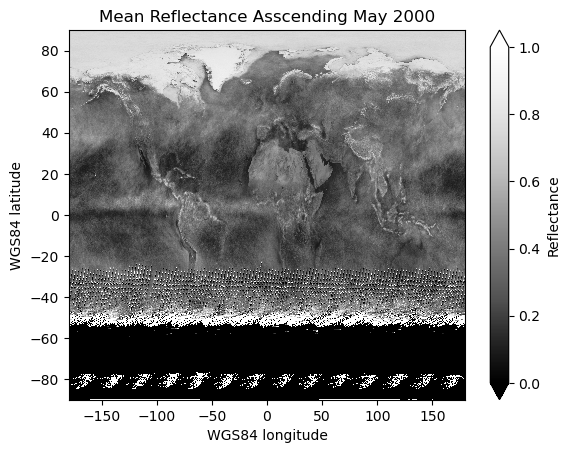

In [26]:
da_refl.mean(dim="time").plot(
    cmap="Greys_r",
    vmin=0,
    vmax=1.0,
    cbar_kwargs={"label": "Reflectance"}
)

pyplot.title("Mean Reflectance Asscending April 2000")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")

pyplot.savefig("mean_reflectance_ascending_200004.png", dpi=300, bbox_inches="tight")
pyplot.show()

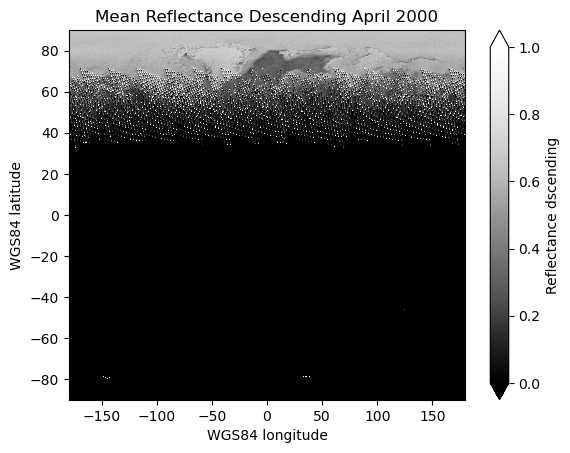

In [153]:
da_refl_desc.mean(dim="time").plot(
    cmap="Greys_r",
    vmin=0,
    vmax=1.0,
    cbar_kwargs={"label": "Reflectance dscending"}
)

pyplot.title("Mean Reflectance Descending April 2000")
pyplot.xlabel("WGS84 longitude")
pyplot.ylabel("WGS84 latitude")

pyplot.savefig("mean_reflectance_descending_200004.png", dpi=300, bbox_inches="tight")
pyplot.show()

In [28]:
da_refl_mean = da_refl.mean(dim="time")

## Calculate transmissivity

In [60]:
t2_04 = (da_refl_mean - 0.08) / (0.65 - 0.08)

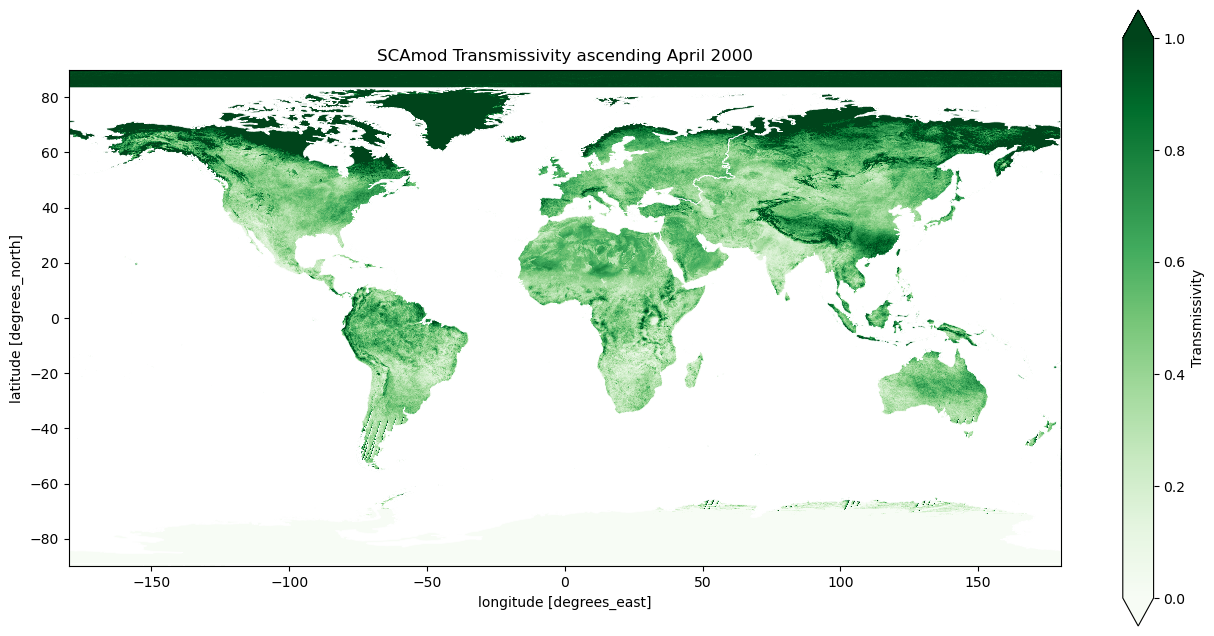

In [33]:
# Convert map to EPSG:4326
Map = Map.to_crs(epsg=4326)

# Create rectangular figure
fig, ax = pyplot.subplots(figsize=(16, 8))

# Plot transmissivity first
t2_04.plot(
    ax=ax,
    cmap="Greens",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"}
)

# Get the extent of the map
xmin, ymin, xmax, ymax = Map.total_bounds

# Create a rectangle covering the whole plotting area
background = gpd.GeoDataFrame(
    geometry=[box(xmin, ymin, xmax, ymax)],
    crs="EPSG:4326"
)

# Create the areas OUTSIDE Map
outside = gpd.overlay(
    background,
    Map[["geometry"]],
    how="difference"
)

# Paint only the outside areas white
outside.plot(
    ax=ax,
    color="white",
    edgecolor="none"
)

# Plot Map boundaries with transparent fill
Map.plot(
    ax=ax,
    facecolor="none",
    edgecolor="white",
    linewidth=0.5
)

# Labels and title
pyplot.title("SCAmod Transmissivity ascending April 2000")

# Save figure
pyplot.savefig(
    "Figures/SCAmod_transmissivity_April_2000.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

pyplot.show()

# Mask clouds

In [29]:
da_cloud = ds_cloud["cma_prob_asc"]

In [149]:
bins = np.arange(0, 1.1, 0.1)   # 0.0, 0.1, ..., 1.0
vals = da_cloud.values.ravel()

nan_mask = np.isnan(vals)
valid = vals[~nan_mask]

counts, edges = np.histogram(valid, bins=bins)
labels = [f"{a:.1f}-{b:.1f}" for a, b in zip(edges[:-1], edges[1:])]

# Add categories for anything outside the bins, plus NaN
below = int((valid < 0).sum())
above = int((valid > 1).sum())

summary = pd.DataFrame({
    "range": ["< 0"] + labels + ["> 1", "NaN"],
    "count": [below] + counts.tolist() + [above, int(nan_mask.sum())],
})
summary["percent"] = (summary["count"] / vals.size * 100).round(2)

print(summary.to_string(index=False))
print(f"\nTotal: {summary['count'].sum()} (array size: {vals.size})")

  range     count  percent
    < 0         0     0.00
0.0-0.1 179653671    23.10
0.1-0.2  35391003     4.55
0.2-0.3  19773873     2.54
0.3-0.4  13167549     1.69
0.4-0.5  10330238     1.33
0.5-0.6   9593324     1.23
0.6-0.7  10119957     1.30
0.7-0.8  12259079     1.58
0.8-0.9  18057620     2.32
0.9-1.0 332868804    42.81
    > 1         0     0.00
    NaN 136384882    17.54

Total: 777600000 (array size: 777600000)


In [150]:
bins = np.round(np.arange(0.90, 1.001, 0.01), 2)   # 0.90, 0.91, ..., 1.00
vals = da_cloud.values.ravel()

nan_mask = np.isnan(vals)
valid = vals[~nan_mask]

counts, edges = np.histogram(valid, bins=bins)
labels = [f"{a:.2f}-{b:.2f}" for a, b in zip(edges[:-1], edges[1:])]

below = int((valid < 0.90).sum())
above = int((valid > 1.00).sum())

summary = pd.DataFrame({
    "range": ["< 0.90"] + labels + ["> 1.00", "NaN"],
    "count": [below] + counts.tolist() + [above, int(nan_mask.sum())],
})
summary["percent"] = (summary["count"] / vals.size * 100).round(2)

print(summary.to_string(index=False))
print(f"\nTotal: {summary['count'].sum()} (array size: {vals.size})")

    range     count  percent
   < 0.90 308346314    39.65
0.90-0.91   2641645     0.34
0.91-0.92   2892728     0.37
0.92-0.93   3308980     0.43
0.93-0.94   3842598     0.49
0.94-0.95   4538119     0.58
0.95-0.96   5603772     0.72
0.96-0.97   7453671     0.96
0.97-0.98  11295467     1.45
0.98-0.99  25159175     3.24
0.99-1.00 266132649    34.22
   > 1.00         0     0.00
      NaN 136384882    17.54

Total: 777600000 (array size: 777600000)


In [30]:
cloud_mask_05 = da_cloud <= 0.5

In [31]:
cloud_mask_06 = da_cloud <= 0.6

In [32]:
cloud_mask_07 = da_cloud <= 0.7

In [33]:
cloud_mask_08 = da_cloud <= 0.8

In [34]:
cloud_mask_09 = da_cloud <= 0.9

In [35]:
da_refl_cloud_05 = da_refl.where(cloud_mask_05)

In [43]:
da_refl_cloud_06 = da_refl.where(cloud_mask_06)

In [44]:
da_refl_cloud_07 = da_refl.where(cloud_mask_07)

In [45]:
da_refl_cloud_08 = da_refl.where(cloud_mask_08)

In [46]:
da_refl_cloud_09 = da_refl.where(cloud_mask_09)

In [47]:
da_refl_mean = da_refl.mean(dim="time")

In [48]:
da_refl_cloud_mean_05 = da_refl_cloud_05.mean(dim="time")

In [49]:
da_refl_cloud_mean_06 = da_refl_cloud_06.mean(dim="time")

In [50]:
da_refl_cloud_mean_07 = da_refl_cloud_07.mean(dim="time")

In [51]:
da_refl_cloud_mean_08 = da_refl_cloud_08.mean(dim="time")

In [52]:
da_refl_cloud_mean_09 = da_refl_cloud_09.mean(dim="time")

In [53]:
t2_cloud_00 = (da_refl_mean - 0.08) / (0.65 - 0.08)

In [54]:
t2_cloud_05 = (da_refl_cloud_mean_05 - 0.08) / (0.65 - 0.08)

In [55]:
t2_cloud_06 = (da_refl_cloud_mean_06 - 0.08) / (0.65 - 0.08)

In [56]:
t2_cloud_07 = (da_refl_cloud_mean_07 - 0.08) / (0.65 - 0.08)

In [57]:
t2_cloud_08 = (da_refl_cloud_mean_08 - 0.08) / (0.65 - 0.08)

In [58]:
t2_cloud_09 = (da_refl_cloud_mean_09 - 0.08) / (0.65 - 0.08)

# Plot Kemijoki transmissivity

In [59]:
area = Kemijoki

In [60]:
Kemijoki_t2_00 = t2_cloud_00.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [61]:
Kemijoki_t2_05 = t2_cloud_05.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [62]:
Kemijoki_t2_06 = t2_cloud_06.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [63]:
Kemijoki_t2_07 = t2_cloud_07.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [64]:
Kemijoki_t2_08 = t2_cloud_08.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [65]:
Kemijoki_t2_09 = t2_cloud_09.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [66]:
# Combine all mask layers into one boolean mask
combined_mask = (
    (ENVEO_ice == 0) |
    (ENVEO_water == 0)
)

# Apply mask: set flagged pixels to NaN so they render white via cmap.set_bad
ENVEO_masked = ENVEO.where(~combined_mask)

In [67]:
ENVEO_t2 = ENVEO_masked.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

In [68]:
Kemijoki_3067_00 = Kemijoki_t2_00.rio.reproject("EPSG:3067")

In [69]:
Kemijoki_3067_05 = Kemijoki_t2_05.rio.reproject("EPSG:3067")

In [70]:
Kemijoki_3067_06 = Kemijoki_t2_06.rio.reproject("EPSG:3067")

In [71]:
Kemijoki_3067_07 = Kemijoki_t2_07.rio.reproject("EPSG:3067")

In [72]:
Kemijoki_3067_08 = Kemijoki_t2_08.rio.reproject("EPSG:3067")

In [73]:
Kemijoki_3067_09 = Kemijoki_t2_09.rio.reproject("EPSG:3067")

In [74]:
ENVEO_3067 = ENVEO_t2.rio.reproject("EPSG:3067")

In [75]:
left = 340000.0
right = 640000.0
top = 7645000.0
bottom = 7295000.0

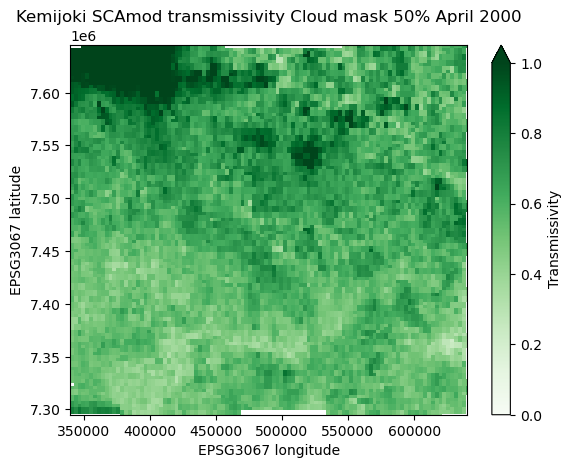

In [76]:
Kemijoki_3067_05.plot.pcolormesh(
    cmap="Greens",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"}
)

pyplot.xlim(left, right)
pyplot.ylim(bottom, top)
pyplot.title("Kemijoki SCAmod transmissivity Cloud mask 50% April 2000")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")

# Save figure
#pyplot.savefig(
    #"Figures/Kemijoki_SCAmod_transmissivity_2000_05_cloud_mask_50.png",
    #dpi=300,
    #bbox_inches="tight",
    #facecolor="white"
#)


pyplot.show()

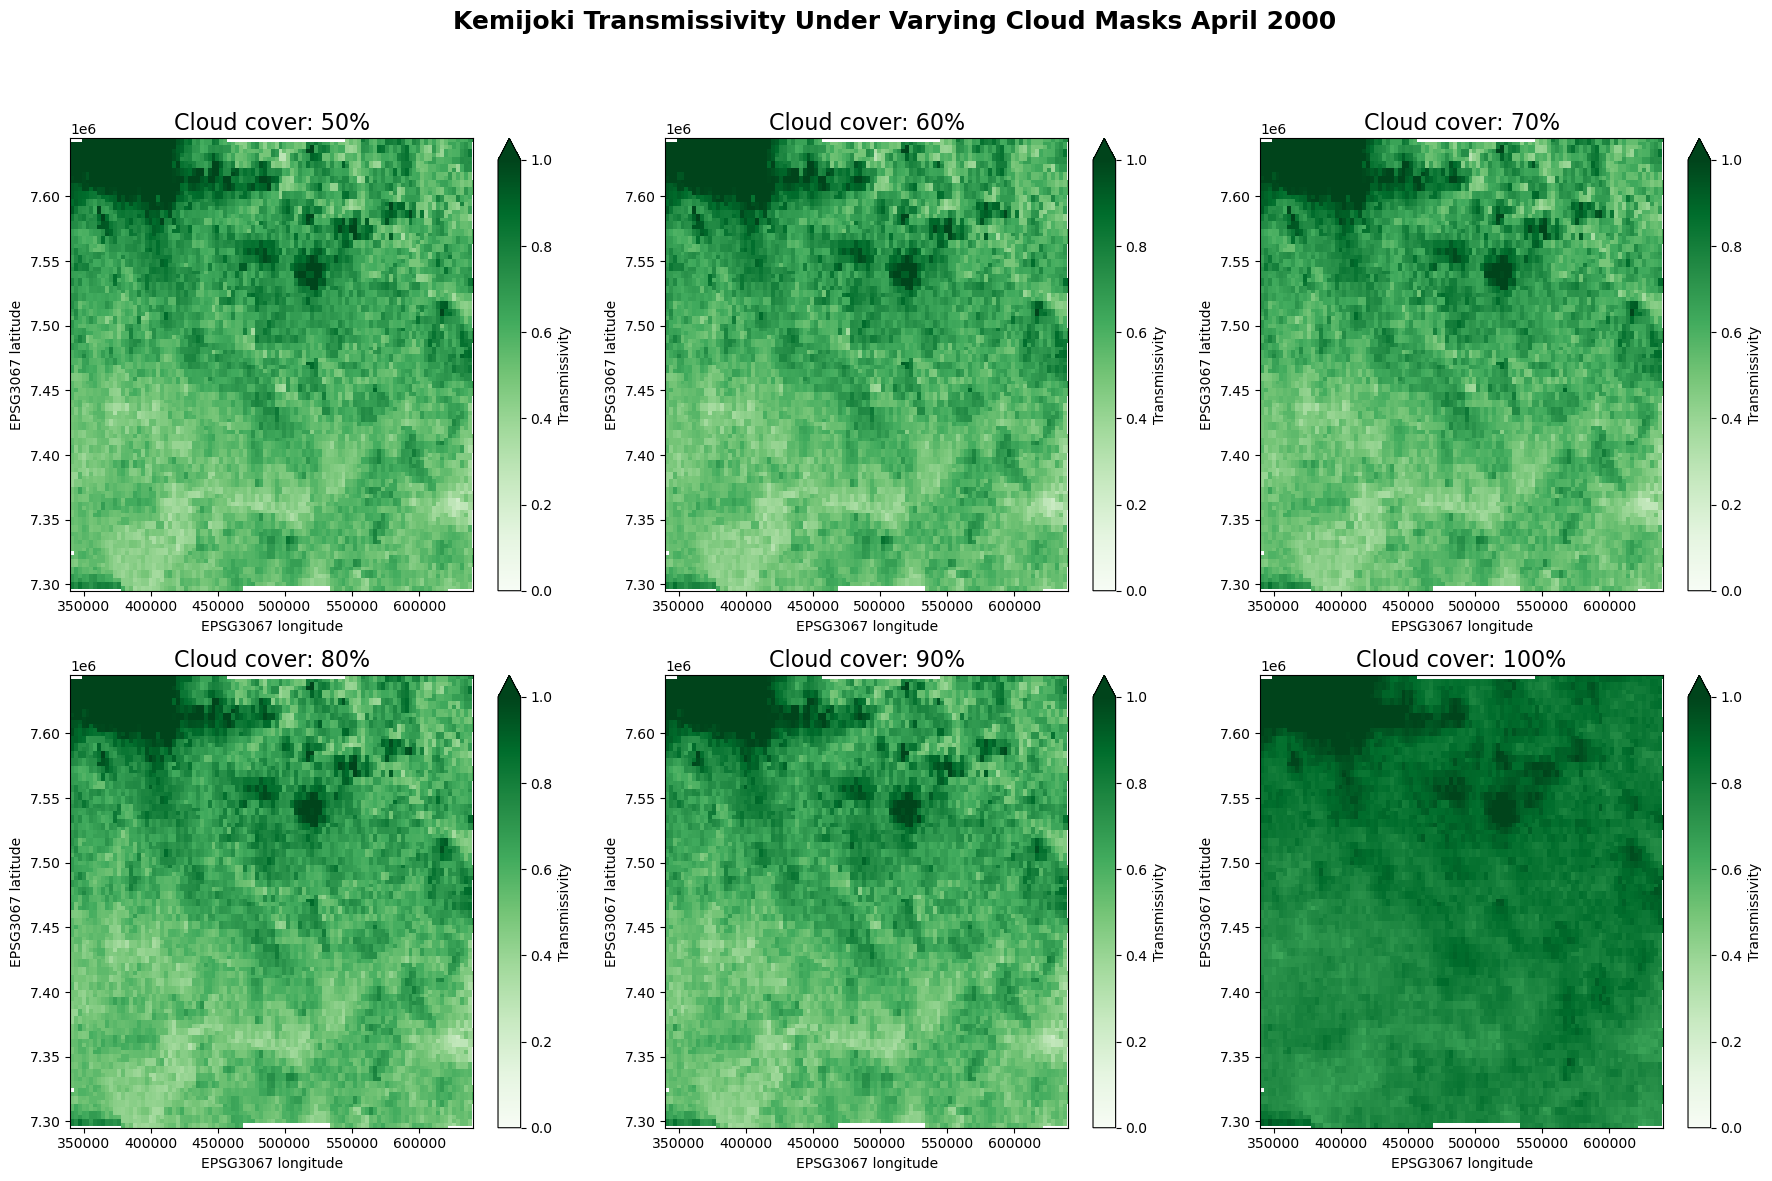

In [77]:
from matplotlib import pyplot

left = 340000.0
right = 640000.0
top = 7645000.0
bottom = 7295000.0

raw_rasters = [
    Kemijoki_3067_05,
    Kemijoki_3067_06,
    Kemijoki_3067_07,
    Kemijoki_3067_08,
    Kemijoki_3067_09,
    Kemijoki_3067_00
]

labels = [50, 60, 70, 80, 90, 100]

fig, axes = pyplot.subplots(2, 3, figsize=(18, 12))

for ax, raster, label in zip(axes.flat, raw_rasters, labels):
    raster.plot.pcolormesh(
        ax=ax,
        cmap="Greens",
        vmin=0,
        vmax=1,
        cbar_kwargs={"label": "Transmissivity"}
    )
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_title(f"Cloud cover: {label}%", fontsize=16)
    ax.set_xlabel("EPSG3067 longitude")
    ax.set_ylabel("EPSG3067 latitude")

# Overall figure title
fig.suptitle(
    "Kemijoki Transmissivity Under Varying Cloud Masks April 2000",
    fontsize=18,
    fontweight="bold"
)

# Add breathing room between subplots
pyplot.subplots_adjust(wspace=0.4, hspace=0.35, top=0.90)

# Layout adjustment must happen before saving
pyplot.tight_layout(rect=[0, 0, 1, 0.94])

# Save figure
pyplot.savefig(
    "Figures/transmissivity_2000_04_cloud_masking.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

pyplot.show()

/local/mpekkala/software/conda/envs/rasterio_env/lib/python3.11/site-packages/matplotlib/colors.py:778: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


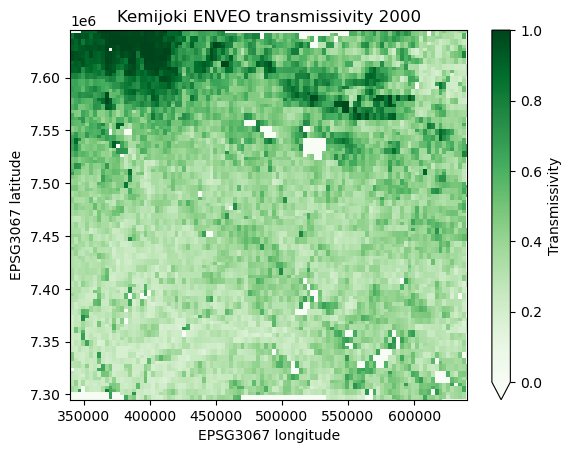

In [78]:
ENVEO_3067.plot(
    cmap="Greens",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"}
)

pyplot.xlim(left, right)
pyplot.ylim(bottom, top)
pyplot.title("Kemijoki ENVEO transmissivity 2000")
pyplot.xlabel("EPSG3067 longitude")
pyplot.ylabel("EPSG3067 latitude")

# Save figure
pyplot.savefig(
    "Figures/Kemijoki_ENVEO_transmissivity_2000.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

pyplot.show()

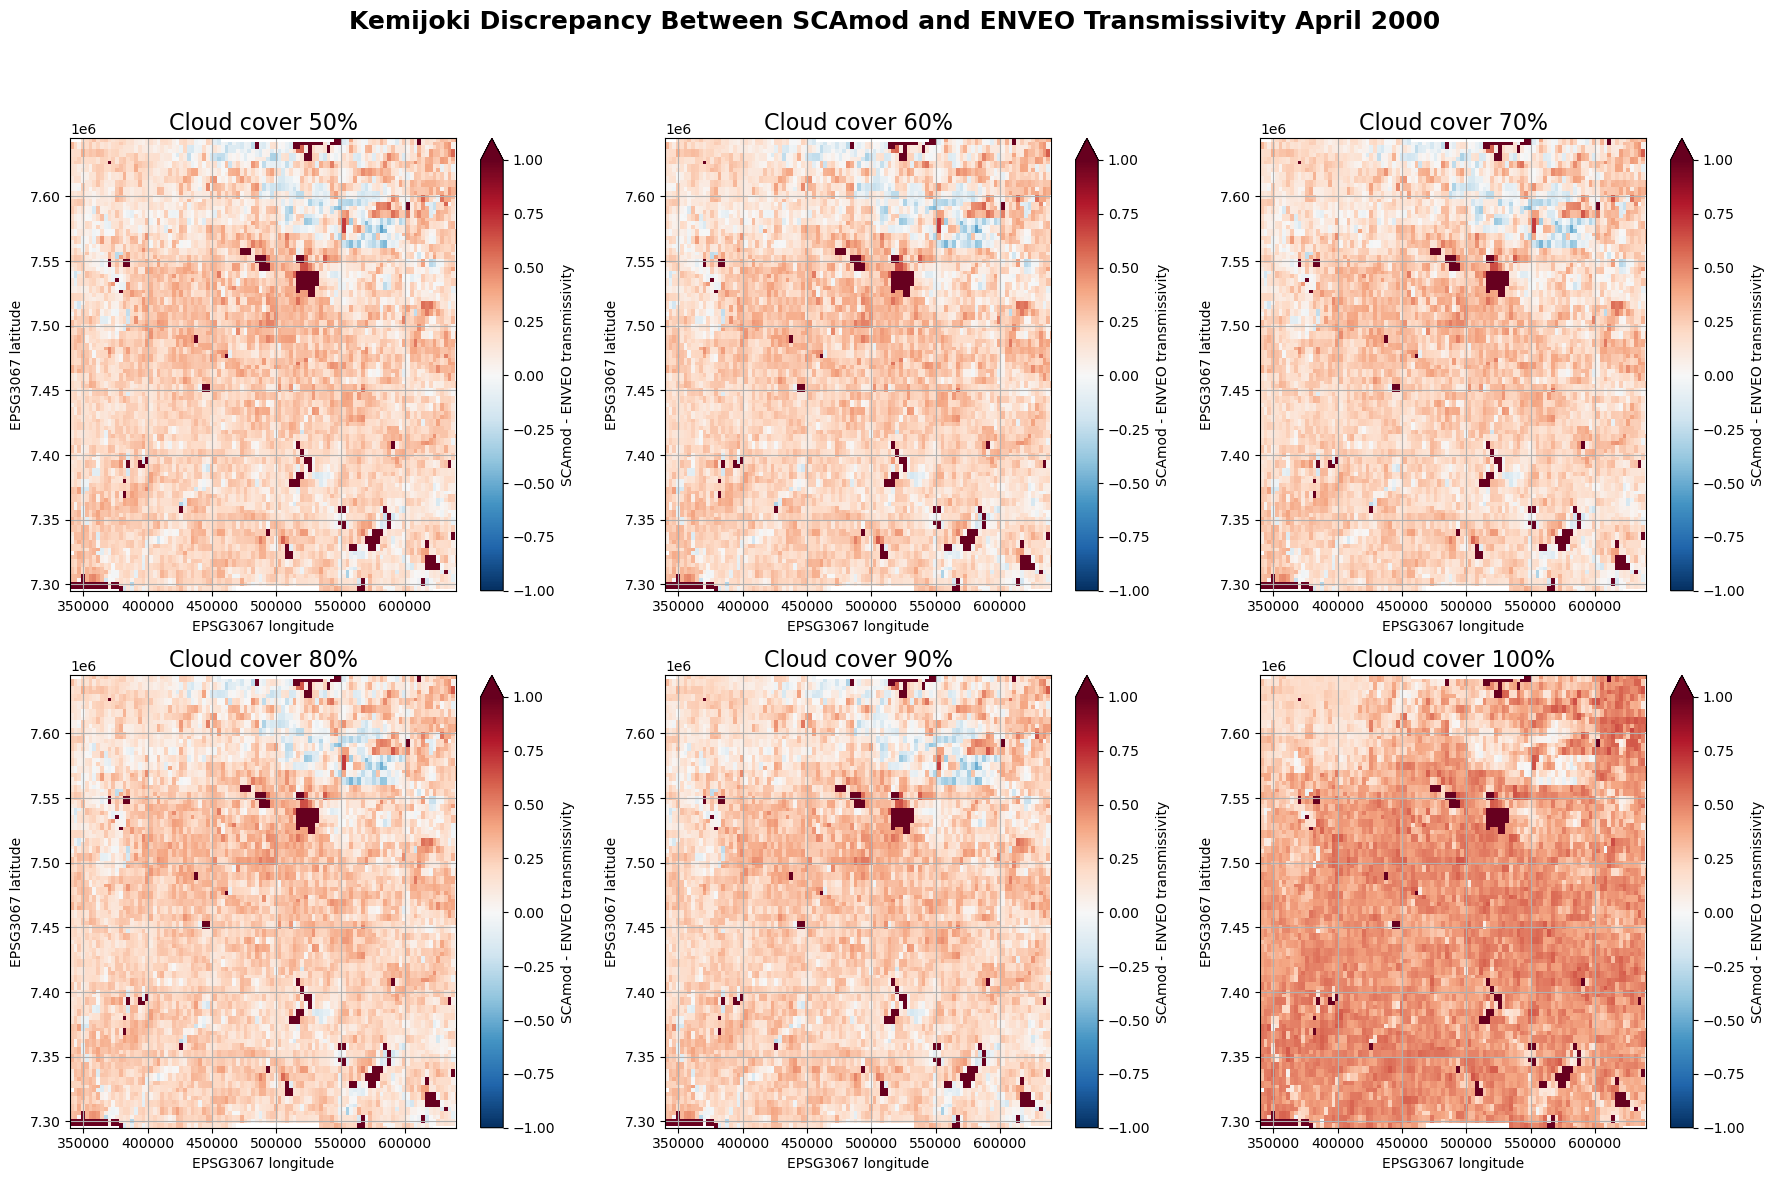

In [79]:
import matplotlib.pyplot as pyplot
import rioxarray

raw_rasters = [
    Kemijoki_3067_05,
    Kemijoki_3067_06,
    Kemijoki_3067_07,
    Kemijoki_3067_08,
    Kemijoki_3067_09,
    Kemijoki_3067_00
]

labels = ["Cloud cover 50%", "Cloud cover 60%", "Cloud cover 70%", "Cloud cover 80%", "Cloud cover 90%", "Cloud cover 100%"]

# Clean ENVEO once (this part doesn't depend on the raster)
ENVEO_clean = ENVEO_3067
if "band" in ENVEO_clean.dims:
    ENVEO_clean = ENVEO_clean.squeeze("band", drop=True)
ENVEO_clean = ENVEO_clean.rio.write_crs("EPSG:3067")

fig, axes = pyplot.subplots(2, 3, figsize=(18, 12))

for ax, raster, label in zip(axes.flat, raw_rasters, labels):
    # Some rasters may already be 2D (no time dim), so check first
    if "time" in raster.dims:
        Kemijoki_mean = raster.mean(dim="time")
    else:
        Kemijoki_mean = raster

    if "band" in Kemijoki_mean.dims:
        Kemijoki_mean = Kemijoki_mean.squeeze("band", drop=True)

    Kemijoki_mean = Kemijoki_mean.rio.write_crs("EPSG:3067")

    # Match ENVEO grid to this specific raster's grid
    ENVEO_match = ENVEO_clean.rio.reproject_match(Kemijoki_mean)
    if "band" in ENVEO_match.dims:
        ENVEO_match = ENVEO_match.squeeze("band", drop=True)

    comparison = Kemijoki_mean - ENVEO_match

    comparison.plot.pcolormesh(
        ax=ax,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        cbar_kwargs={"label": "SCAmod - ENVEO transmissivity"}
    )

    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_title(f"{label}", fontsize=16)
    ax.set_xlabel("EPSG3067 longitude")
    ax.set_ylabel("EPSG3067 latitude")
    ax.grid(True)

# Overall figure title
fig.suptitle(
    "Kemijoki Discrepancy Between SCAmod and ENVEO Transmissivity April 2000",
    fontsize=18,
    fontweight="bold"
)

# Add breathing room between subplots
pyplot.subplots_adjust(wspace=0.4, hspace=0.35, top=0.90)

# Layout adjustment must happen before saving/showing
pyplot.tight_layout(rect=[0, 0, 1, 0.94])

# Save figure
pyplot.savefig(
    "Figures/transmissivity_discrepancies_ENVEO_SCAmod_2000_04.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

pyplot.show()